# 14 | Recommended FC stability analysis and clinical interpretation

**Question:** Which temporal perturbation matches our descriptive goal after diagnosing PC retraining?

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## Recommendation and target
Use **nonreplacement block subsets of 97 distinct eligible frames per session**, with complete WM/CSF temporal preprocessing, scaling, five-PC extraction and final regression refitted in every draw. Tile the original 180-frame axis into ten-frame blocks with a random circular origin; permute tiles once, omit censored frames and trim the final tile. Derivatives and DCT terms keep their original acquisition coordinates. Images, masks, motion and censor eligibility stay fixed.

Repeated bootstrap rows concentrate the empirical covariance used to learn PCs. Nonreplacement subsets remove that multiplicity mechanism; freezing full-pool training conditions on information outside the subset. A common count matches duration: floor(two-thirds × min(146,150))=97 frames, 3.88 minutes retained exposure, 58 algebraic residual directions after rank-39 regression. Two-thirds approximates previous 94/96 distinct coverage with a meaningful omitted fraction. This is a **post hoc engineering compromise**, saved in the policy before these new contrasts; no claim of optimality or calibrated coverage is made.

The target is **conditional stability of shorter-sample estimators**, not a full-run confidence interval or bias-corrected full-run outcome. Subsets overlap and the 500×200 grid cells are dependent. No probability of a biological direction, independent frame count, clinical effect or predictive model is estimated. Higher retention often narrows ranges because draws approach the fixed observed data; it cannot select a favourable sign.

version                                                    fixed-duration-nonreplacement-refit-v1
primary_protocol                                                               two_thirds_block10
primary_mode                                                                           full_refit
primary_support                                                                             fixed
eligible_frames                                                                        [146, 150]
targets                                         {'half': 73, 'two_thirds': 97, 'four_fifths': ...
primary_distinct_frames                                                                        97
primary_retained_minutes                                                                     3.88
primary_block_frames                                                                           10
block_seconds                                                                                  24
SC_draws            

protocol                two_thirds_block10
mode                            full_refit
support                              fixed
role                               primary
SC_draws                               500
FC_draws                               200
q025                             -0.102611
median                           -0.046938
q975                              0.008316
sd                                0.027477
positive_fraction                  0.04236
SC_variance                       0.000009
FC_variance                       0.000742
interaction_variance              0.000004
total_variance                    0.000755
SC_share                          0.011832
FC_share                          0.983262
interaction_share                 0.004906
dtype: object

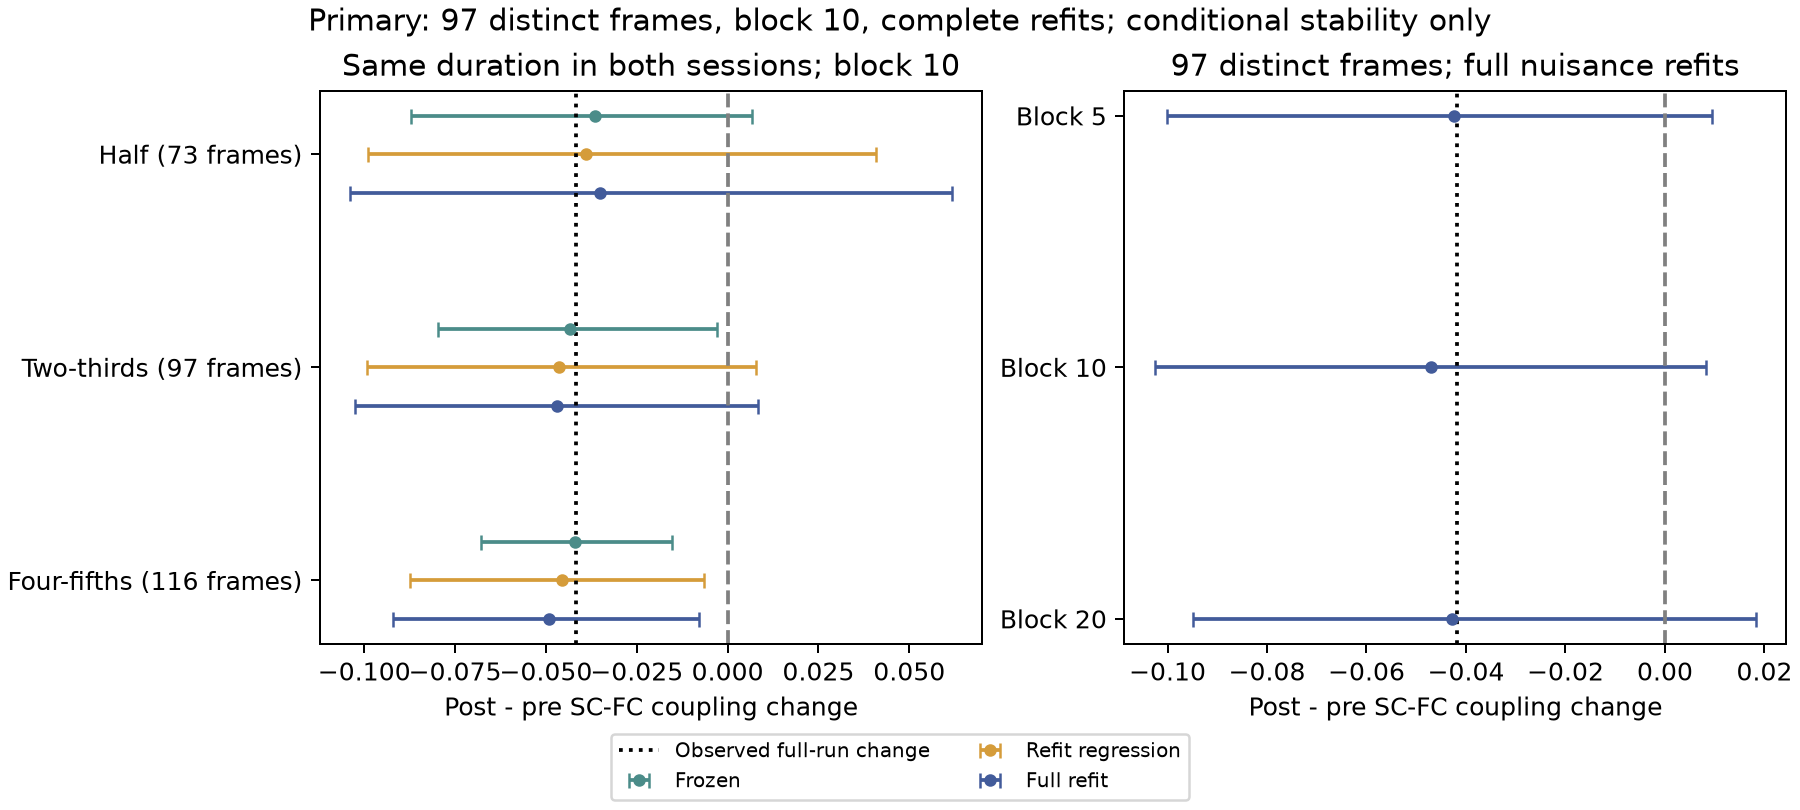

Observed full-run estimates are separate from subset medians and ranges.


In [2]:
PFC=RESULTS/"primary_fc"
policy=json.loads((PFC/"main_summary.json").read_text())
display(pd.Series(policy["policy"]))
display(pd.Series(policy["primary_joint_coupling"]))
display(Image(filename=str(RESULTS/"figures/primary_fc_joint.png")))
print("Observed full-run estimates are separate from subset medians and ranges.")

## Compare the specified sensitivities
The primary SC policy is unchanged: 823 fixed common-consensus edges with each session's all-run mean seed-rate weights, crossed with 500 whole-run SC bootstrap draws. Each of the nine new temporal designs has 200 draws per session; the index pairs independent session draws rather than physiological moments. The modes use identical subsets: frozen residuals, regression coefficients refitted with fixed PC scores, or complete nuisance refits.

Select common retained fraction and block length. `reselected` SC is available only for the primary full-refit FC branch. Previous bootstraps, unit-weight exact coverage, independent bootstrap-count-matched subsets, original session-specific 80% retention and 68-frame duration/FD/run-half matching remain in the catalog. The primary matches duration, **not motion**; matching sensitivities answer complementary conditional questions.

,protocol,mode,support,role,SC_draws,FC_draws,q025,median,q975,sd,positive_fraction,SC_variance,FC_variance,interaction_variance,total_variance,SC_share,FC_share,interaction_share
14,two_thirds_block10,full_refit,fixed,primary,500,200,-0.102611,-0.046938,0.008316,0.027477,0.04236,0.000009,0.000742,0.000004,0.000755,0.011832,0.983262,0.004906


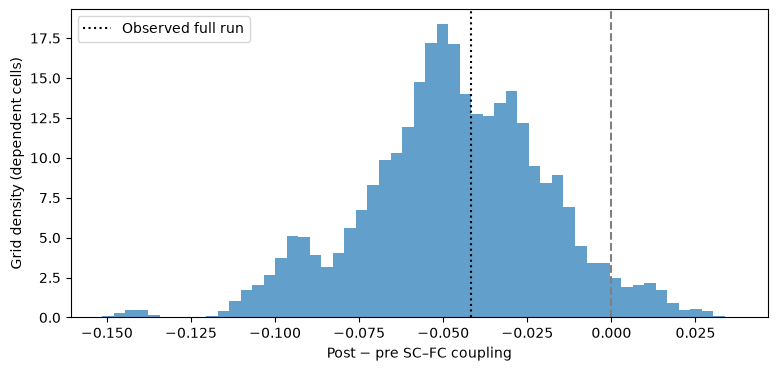

interactive(children=(Dropdown(description='fraction', index=1, options=('half', 'two_thirds', 'four_fifths'),…

family                                 role       
68_frame_duration_FD_run_half_matched  sensitivity    12
fixed_common_duration_nonreplacement   primary         1
                                       sensitivity    27
prior_PC_sampling_controls             sensitivity    39
Name: designs, dtype: int64

In [3]:
pfc_summary=pd.read_csv(PFC/"summary.csv")
def compare_primary(fraction="two_thirds",block=10,mode="full_refit",support="fixed"):
    protocol=f"{fraction}_block{block}"
    v=pfc_summary[(pfc_summary.protocol==protocol)&(pfc_summary["mode"]==mode)&(pfc_summary.support==support)]
    if v.empty:print("SC reselection is available for two_thirds/block10/full_refit only.");return
    display(v)
    grid=np.load(PFC/f"{protocol}_{support}_{mode}.npz")
    plt.hist(grid["delta"].ravel(),bins=55,density=True,alpha=.7)
    plt.axvline(policy["policy"]["observed_coupling"]["delta"],color="black",ls=":",label="Observed full run")
    plt.axvline(0,color="gray",ls="--");plt.xlabel("Post − pre SC–FC coupling");plt.ylabel("Grid density (dependent cells)");plt.legend();plt.show();plt.close()
widgets.interact(compare_primary,fraction=widgets.Dropdown(options=["half","two_thirds","four_fifths"],value="two_thirds"),block=widgets.Dropdown(options=[5,10,20],value=10),mode=widgets.Dropdown(options=["frozen","coefficients","full_refit"],value="full_refit"),support=widgets.Dropdown(options=["fixed","reselected"]))
catalog=pd.read_csv(PFC/"sensitivity_catalog.csv")
display(catalog.groupby(["family","role"]).size().rename("designs"))

Distinct frames: 97 ; exposure (min): 3.88


,protocol,fraction,block,mode,session,draw,target,eligible,design_rank,distinct_rows_minus_rank,...,rows_minus_rank,reason,design_condition,tissue_voxels,PC_variance_fraction_sum,minimum_ROI_residual_SD,PCA5_fraction,gap5_relative,adjusted_PC_cos2_min,adjusted_PC_cos2_mean
4800,two_thirds_block10,two_thirds,10,frozen,preop,0,97,True,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4801,two_thirds_block10,two_thirds,10,coefficients,preop,0,97,True,39.0,58.0,...,58.0,eligible,534.413228,NaN,NaN,0.688662,NaN,NaN,NaN,NaN
4802,two_thirds_block10,two_thirds,10,full_refit,preop,0,97,True,39.0,58.0,...,58.0,eligible,574.585204,NaN,NaN,0.662054,0.168201,0.012396,0.000319,0.734896


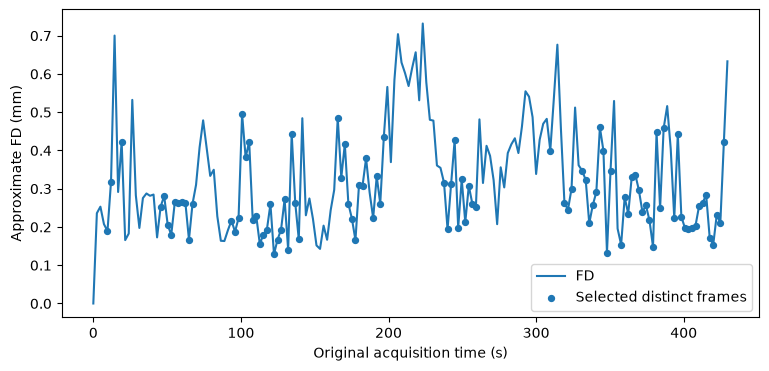

interactive(children=(Dropdown(description='session', options=('preop', 'postop'), value='preop'), IntSlider(v…

<function __main__.inspect_subset(session='preop', draw=0, fraction='two_thirds', block=10)>

In [4]:
from pat16.primary_fc import PROTOCOLS
frame_weights=np.load(PFC/"frame_weights.npy")
fit_qc=pd.read_csv(PFC/"fit_metrics.csv")
def inspect_subset(session="preop",draw=0,fraction="two_thirds",block=10):
    protocol=f"{fraction}_block{block}";w=frame_weights[PROTOCOLS.index(protocol),SESSIONS.index(session),draw]
    keep=np.load(RESULTS/session/"fc_primary_keep.npy");fd=np.load(RESULTS/session/"fd.npy")
    assert w.max()==1 and keep[w>0].all()
    print("Distinct frames:",int(w.sum()),"; exposure (min):",w.sum()*2.4/60)
    display(fit_qc[(fit_qc.protocol==protocol)&(fit_qc.session==session)&(fit_qc.draw==draw)])
    plt.plot(np.arange(180)*2.4,fd,label="FD");plt.scatter(np.where(w)[0]*2.4,fd[w>0],s=18,label="Selected distinct frames");plt.xlabel("Original acquisition time (s)");plt.ylabel("Approximate FD (mm)");plt.legend();plt.show();plt.close()
widgets.interact(inspect_subset,session=widgets.Dropdown(options=SESSIONS),draw=widgets.IntSlider(min=0,max=199),fraction=widgets.Dropdown(options=["half","two_thirds","four_fifths"],value="two_thirds"),block=widgets.Dropdown(options=[5,10,20],value=10))

## Clinical integration: observations remain measurements
Observed coupling Δ=−0.04173; recommended subset median −0.04694, range [−0.10261,+0.00832]. FC accounts for 98.33% of conditional crossed-grid variance, only under these perturbations. Sensorimotor range [−0.2064,−0.0170] coexists with slower MOT but faster RTI; a previous matched-count range crossed zero. Visual median −0.0209 is much closer to observed −0.0045 than the repeated-row median −0.1993. Visual, control and default primary ranges cross zero, while dorsal-attention is negative. Seven exploratory dependent network summaries do not identify a task-specific mechanism.

SSP 6→7, mixed SOC/RVP, anxiety 36→30, worry 54→61, loneliness 40→50 and employed→sick leave are different outcomes. Preserve all 47 source fields, units, missingness, RTI ceilings and unverified ERQ/education codes. No QoL composite, two-point correlation, reliable-change inference or causal surgery claim is supported. Appendices A1/A2 and notebook 04 retain the complete dictionaries.

In [5]:
clinical=pd.read_csv(PFC/"clinical_evidence_ledger.csv")
nr=pd.read_csv(PFC/"network_uncertainty.csv").query("role=='primary'")
display(Image(filename=str(RESULTS/"figures/primary_fc_network_changes.png")))
def clinical_primary(measure="rti_simple_rt_mean"):
    row=clinical[clinical.measure==measure].iloc[0]
    display(row.to_frame("Source and interpretation"))
    if pd.isna(row.candidate_networks):print("Unlocalized contextual evidence; no network effect or QoL score is inferred.");return
    display(nr[nr.network.isin(row.candidate_networks.split("; "))])
widgets.interact(clinical_primary,measure=widgets.Dropdown(options=clinical.measure.tolist(),value="rti_simple_rt_mean"))

,Source and interpretation
measure,rti_simple_rt_mean
description,CANTAB Reaction Time — simple: mean reaction time
group,CANTAB
source_units,ms
preop,403.78
postop,345.5555555556
delta_post_minus_pre,-58.224444
percent_change,-14.419844
favorable_direction,-1.0
direction_aligned_percent,14.419844


,network,modality,protocol,mode,role,units,edges,preop,postop,observed_delta,draws,q025,median,q975,sd,positive_fraction
28,SomMot,SC,whole_run_bootstrap,own_reselected,primary,mean streamlines / 10000 attempted seeds,91,2.579487,2.915751,0.336264,500,0.283402,0.327839,0.371245,0.023036,1.00
43,SomMot,FC,two_thirds_block10,full_refit,primary,mean Fisher z,91,0.265161,0.149400,-0.115760,200,-0.206384,-0.109317,-0.016997,0.051992,0.01
56,DorsAttn,SC,whole_run_bootstrap,own_reselected,primary,mean streamlines / 10000 attempted seeds,105,1.707143,1.041746,-0.665397,500,-0.712429,-0.665317,-0.623627,0.022194,0.00
71,DorsAttn,FC,two_thirds_block10,full_refit,primary,mean Fisher z,105,0.254676,0.183384,-0.071292,200,-0.239322,-0.123442,-0.004977,0.062481,0.02
84,SalVentAttn,SC,whole_run_bootstrap,own_reselected,primary,mean streamlines / 10000 attempted seeds,66,2.034848,2.172980,0.138131,500,0.082298,0.136995,0.187386,0.027526,1.00
99,SalVentAttn,FC,two_thirds_block10,full_refit,primary,mean Fisher z,66,0.202582,0.147258,-0.055324,200,-0.167222,-0.074004,0.031901,0.051650,0.11


interactive(children=(Dropdown(description='measure', index=23, options=('stai', 'pswq', 'erq_reappraisal', 'e…

<function __main__.clinical_primary(measure='rti_simple_rt_mean')>

## Reproduce and extend
`uv run python scripts/recommend_primary_fc.py` verifies hashes and reuses the checkpoint; `--force` recomputes all nine temporal designs and all paired nuisance modes. `scripts/plot_primary_fc.py` redraws figures. `scripts/run_all.py --notebooks --report` rebuilds the complete current package. See `docs/REPRODUCING.md` for clone/setup, runtime assets, external FSL and TeX requirements. The public source is https://github.com/arvidl/glioma-connectivity-and-cognition; the paper PDF is tracked by ordinary Git. Seven checksummed runtime parts are provided in release `v0.1.0-assets` and restored with `python3 scripts/fetch_data.py`.

**Exercise:** compare 73, 97 and 116 frames with frozen and full refits. Explain why a narrower negative range at high retention does not validate a biological sign. Then inspect a contextual field with no network assignment and list what future measurements would be needed to test a clinical hypothesis.